In [ ]:
# what are the category percentages of ladd and pia flights??

# what is the percentile distrubtion of altitudes
# what is the percentage distrubtion of calcualted speeds. 
# We could do this on already labelled flights with the basic algorithm. 

In [6]:
from datetime import date
import polars as pl
dates = [
    date(2026, 3, 1),
    date(2026, 6, 1),
]
from data_engineering.adsb.read_adsb import read_adsb
from data_engineering.flights.flight_type import get_flights

dfs = [get_flights(d) for d in dates]

df = pl.concat(dfs)

In [ ]:
df_adsb = pl.concat([read_adsb(d, pia_or_american_ladd_only=True) for d in dates])

time,icao,registration,callsign,lat,lon,baro_altitude_ft,on_ground,ground_speed_kt,track_deg,aircraft_type,aircraft_description,owner,category,pia,ladd,military,interesting
datetime[ms],str,str,str,f64,f64,i32,bool,f32,f32,str,str,str,str,bool,bool,bool,bool
2026-03-01 16:43:56.720,"""a0001a""","""N1AZ""","""CXF1""",33.629313,-111.908183,null,true,5.2,84.400002,"""FA7X""","""DASSAULT Falcon 7X""","""WILMINGTON TRUST CO TRUSTEE""","""A2""",false,true,false,false
2026-03-01 16:43:58.090,"""a0001a""","""N1AZ""",null,33.629311,-111.90814,null,true,5.2,87.199997,"""FA7X""","""DASSAULT Falcon 7X""","""WILMINGTON TRUST CO TRUSTEE""",null,false,true,false,false
2026-03-01 16:44:04.450,"""a0001a""","""N1AZ""",null,33.629313,-111.907969,null,true,5.2,90.0,"""FA7X""","""DASSAULT Falcon 7X""","""WILMINGTON TRUST CO TRUSTEE""",null,false,true,false,false
2026-03-01 16:44:17.090,"""a0001a""","""N1AZ""",null,33.629313,-111.907611,null,true,4.8,90.0,"""FA7X""","""DASSAULT Falcon 7X""","""WILMINGTON TRUST CO TRUSTEE""",null,false,true,false,false
2026-03-01 16:44:27.070,"""a0001a""","""N1AZ""","""CXF1""",33.629311,-111.907299,null,true,6.2,90.0,"""FA7X""","""DASSAULT Falcon 7X""","""WILMINGTON TRUST CO TRUSTEE""","""A2""",false,true,false,false
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-06-01 15:18:25.900,"""adf658""","""N999ZG""",null,39.241395,-86.844666,4800,false,257.799988,96.699997,"""B350""","""BEECHCRAFT Super King Air 350""","""CFC LLC""",null,false,true,false,false
2026-06-01 15:18:27.410,"""adf658""","""N999ZG""",null,39.241209,-86.842285,4750,false,255.699997,96.5,"""B350""","""BEECHCRAFT Super King Air 350""","""CFC LLC""",null,false,true,false,false
2026-06-01 15:18:37.110,"""adf658""","""N999ZG""",null,39.239859,-86.827942,4475,false,252.800003,96.800003,"""B350""","""BEECHCRAFT Super King Air 350""","""CFC LLC""","""A1""",false,true,false,false


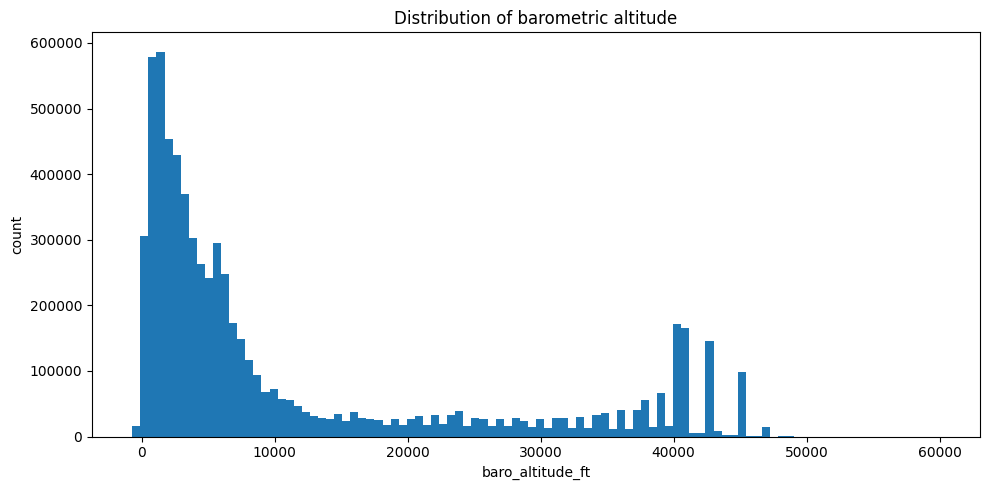

In [12]:
import matplotlib.pyplot as plt

altitudes = (
    df_adsb
    .get_column("baro_altitude_ft")
    .drop_nulls()
    .to_numpy()
)

plt.figure(figsize=(10, 5))
plt.hist(altitudes, bins=100)
plt.xlabel("baro_altitude_ft")
plt.ylabel("count")
plt.title("Distribution of barometric altitude")
plt.tight_layout()
plt.show()

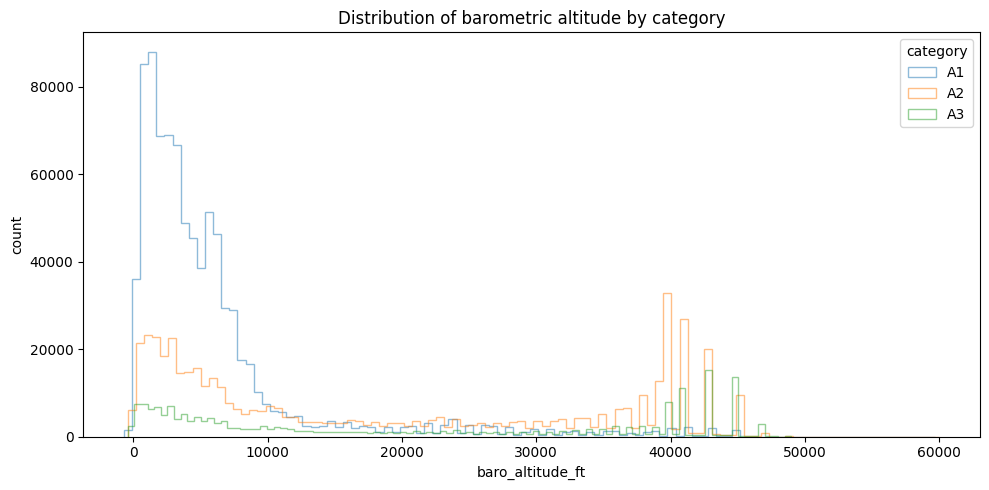

In [13]:
import polars as pl
import matplotlib.pyplot as plt

df_plot = (
    df_adsb
    .filter(
        pl.col("category").is_in(["A1", "A2", "A3"])
        & pl.col("baro_altitude_ft").is_not_null()
    )
    .select(["category", "baro_altitude_ft"])
)

plt.figure(figsize=(10, 5))

for category in ["A1", "A2", "A3"]:
    altitudes = (
        df_plot
        .filter(pl.col("category") == category)
        .get_column("baro_altitude_ft")
        .to_numpy()
    )

    plt.hist(
        altitudes,
        bins=100,
        alpha=0.5,
        label=category,
        histtype="step",
    )

plt.xlabel("baro_altitude_ft")
plt.ylabel("count")
plt.title("Distribution of barometric altitude by category")
plt.legend(title="category")
plt.tight_layout()
plt.show()

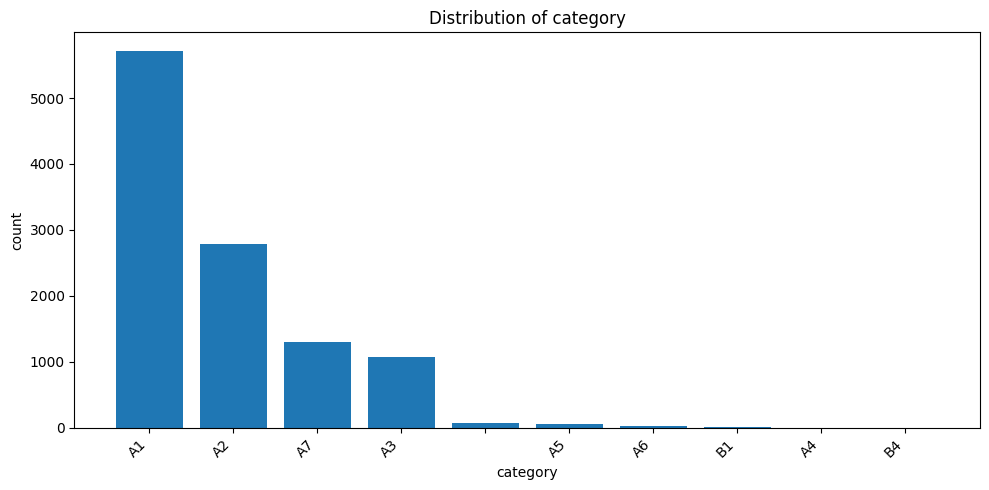

In [9]:
import polars as pl
import matplotlib.pyplot as plt

counts = (
    df.get_column("category")
    .value_counts()
    .sort("count", descending=True)
)

pdf = counts.to_pandas()

plt.figure(figsize=(10, 5))
plt.bar(pdf["category"].astype(str), pdf["count"])
plt.xlabel("category")
plt.ylabel("count")
plt.title("Distribution of category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()